# Transcript Matching — Model Diagnostics
Diagnostics for the production logistic-regression classifier trained by
`scripts/train_matching_model.py` (run that first).

**Inputs:** `data/model.pkl`, `data/best_thr.txt`, `data/pairs_of_transcripts/training_pairs.jsonl`  
**Outputs:** diagnostic plots


## 1. Imports & Setup

In [1]:
import os
import sys
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, confusion_matrix

module_path = os.path.abspath(os.path.join(''))
if module_path not in sys.path:
    sys.path.append(module_path)

if os.path.isdir("../data/"):
    os.chdir("../")

from notebooks.plots_utils import *
from src.utils import video_url
from scripts.train_matching_model import FEATURE_COLUMNS, MODEL_PATH, THRESHOLD_PATH, TRAINING_PAIRS_PATH

%load_ext autoreload
%autoreload 2

rcParams, column_width, page_width, shorts_style, RV_style = get_plt_attr()
plt.rcParams.update(rcParams)

## 2. Load Model Artefacts & Training Pairs

In [2]:
with open(MODEL_PATH, 'rb') as f:
    model = pickle.load(f)
with open(THRESHOLD_PATH) as f:
    best_thr = float(f.read())

labeled_pairs = pd.read_json(TRAINING_PAIRS_PATH, lines=True, dtype={'videoId1': str, 'videoId2': str})
X_all = labeled_pairs[FEATURE_COLUMNS]
y_all = labeled_pairs['label_binary']

print(f"Total labeled pairs: {len(labeled_pairs)}, {int(y_all.sum())} positive and {int((y_all == 0).sum())} negative")
print(f"Best threshold: {best_thr:.4f}")
print("Model coefficients:")
for feat, coef in zip(model.feature_names_in_, model.coef_[0]):
    print(f"  {feat:30s} {coef:+.4f}")
print(f"  {'intercept':30s} {model.intercept_[0]:+.4f}")

Total labeled pairs: 306, 110 positive and 196 negative
Best threshold: 0.7933
Model coefficients:
  partialratio_cut_t1            +0.2396
  partialratio_cut_t2            +0.1141
  sortratio_cut_t1               +0.0252
  sortratio_cut_t2               +0.0289
  setratio_cut_t1                +0.1094
  setratio_cut_t2                +0.1504
  intercept                      -38.6316


In [3]:
print("Class balance:")
display(labeled_pairs.groupby(['diffchannel', 'label_binary']).size().to_frame('count'))

Class balance:


count
diffchannel label_binary       
False       0               120
            1                79
True        0                76
            1                31

## 3. Threshold Selection

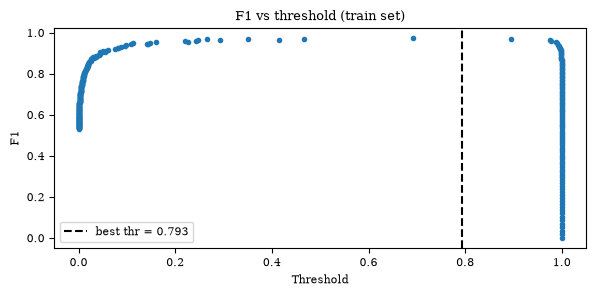

In [4]:
predicted_probas = model.predict_proba(X_all)[:, 1]
prec, rec, thr = precision_recall_curve(y_all, predicted_probas)
f1 = 2 * prec * rec / (prec + rec)

plt.figure(figsize=(6, 3))
plt.plot(thr, f1[1:], '.')
plt.axvline(best_thr, color='k', linestyle='--', label=f'best thr = {best_thr:.3f}')
plt.xlabel('Threshold')
plt.ylabel('F1')
plt.title('F1 vs threshold (train set)')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Diagnostics

In [5]:
labeled_pairs['predicted_proba'] = predicted_probas
labeled_pairs['predicted_label'] = (predicted_probas >= best_thr).astype(int)

acc = (labeled_pairs['predicted_label'] == y_all).mean()
print(f"Train accuracy at best_thr: {acc:.4f}")
print("\nConfusion matrix (train):")
print(confusion_matrix(y_all, labeled_pairs['predicted_label']))

Train accuracy at best_thr: 0.9804

Confusion matrix (train):
[[196   0]
 [  6 104]]


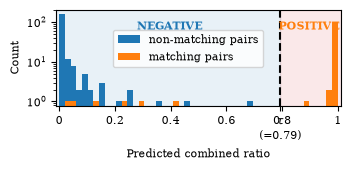

In [6]:
# Decision-boundary histogram
fig, ax = plt.subplots(figsize=(column_width, 1.5))
bin_edges = np.linspace(0, 1, 50)

ax.axvspan(-0.01, best_thr, color='tab:blue', alpha=0.1)
ax.axvspan(best_thr, 1.01, color='tab:red',  alpha=0.1)

ax.hist(labeled_pairs[y_all == 0]['predicted_proba'], bins=bin_edges, label='non-matching pairs')
ax.hist(labeled_pairs[y_all == 1]['predicted_proba'], bins=bin_edges, label='matching pairs')
ax.axvline(best_thr, color='k', linestyle='--')

ax.set_xlabel('Predicted combined ratio')
ax.set_ylabel('Count')
ax.set_yscale('log')
ax.set_xlim(-0.01, 1.01)
ax.set_xticks(
    [0, 0.2, 0.4, 0.6, 0.8, 1, best_thr],
    ['0', '0.2', '0.4', '0.6', '0.8', '1', r'$\tau$' + f'\n(={best_thr:.2f})']
)
ax.text(best_thr / 2, 65, 'NEGATIVE', color='tab:blue', fontdict={'fontweight': 'bold'}, ha='center')
ax.text(best_thr + (1 - best_thr) / 2, 65, 'POSITIVE', color='tab:orange', fontdict={'fontweight': 'bold'}, ha='center')
ax.legend(loc=(0.2, 0.4))
plt.tight_layout(pad=0, w_pad=-0.5, h_pad=0)
fig.savefig('Figures/decision_boundary_plot.pdf', bbox_inches='tight')
plt.show()

In [7]:
# Inspect misclassified pairs
misclassified_cols = [
    'label_binary', 'videoId1', 'videoId2',
    'transcript_clean1', 'transcript_clean2',
    *FEATURE_COLUMNS,
    'predicted_proba', 'predicted_label',
]
misclassified = labeled_pairs[
    labeled_pairs['predicted_label'] != labeled_pairs['label_binary']
][misclassified_cols]
print(f"{len(misclassified)} misclassified pairs")

misclassified['videoId1'] = misclassified['videoId1'].apply(video_url)
misclassified['videoId2'] = misclassified['videoId2'].apply(video_url)
display(misclassified)

6 misclassified pairs


,label_binary,videoId1,videoId2,transcript_clean1,transcript_clean2,partialratio_cut_t1,partialratio_cut_t2,sortratio_cut_t1,sortratio_cut_t2,predicted_proba,predicted_label
14,1,https://www.youtube.com/watch?v=AArrrFHi-xU,https://www.youtube.com/watch?v=hxc3jq8X6og,certains vont dire mais et ben voila encore un...,salut a tous salut le chat bienvenue dans le t...,48,48,2,59,0.414256,0
75,1,https://www.youtube.com/watch?v=3wbYPZ2YiMM,https://www.youtube.com/watch?v=-7h5E2UXYJU,vous etes aussi l'homme au 900 milliards d'eur...,on accueille notre invite rmc l'invite des gra...,48,48,5,40,0.031329,0
86,1,https://www.youtube.com/watch?v=CuVBg9evC5w,https://www.youtube.com/watch?v=qUNVaXlvpkY,en parlant d'amour nous sommes tous des palest...,et bienvenue est-ce qu'on m'entend bien est-ce...,48,47,2,44,0.054729,0
148,1,https://www.youtube.com/watch?v=A0qaMnrgSyY,https://www.youtube.com/watch?v=jDCXGgiDgDY,il est hors de question tous les 5 ans de refa...,vous avez dit tout a l'heure a propos de ce qu...,46,48,50,4,0.293364,0
174,1,https://www.youtube.com/watch?v=BsKvl34K9jw,https://www.youtube.com/watch?v=6W8Lgi8xp9Q,bonjour rfhael gluxman bonjour la france fra...,vous avez l'opportunite de tourner la page de ...,49,49,26,2,0.141431,0
198,1,https://www.youtube.com/watch?v=fDfd-TPiCKs,https://www.youtube.com/watch?v=2I1NQxZUVx8,a bon l'essentiel vous a ete dit et me v...,ecoutez on est en train de faire quelque cho...,55,56,41,51,0.226334,0
